# Neural coding

## References:

### Convolutional Neural Networks (CNN)
Convolutional Neural Networks (CNNs) are a class of deep neural networks primarily used for tasks involving structured data, such as image and audio processing, where spatial or temporal hierarchies exist in the data. CNNs are particularly effective because they use convolutional layers that apply filters to input data to automatically detect and learn relevant patterns (e.g., edges in images, spectral features in audio) without requiring extensive preprocessing.

### Convolutional autoencoder
A neural network with unsupervised training, which means that we don't need to supply a target function. There is only a training set, which is also the target set. A convolutional autoencoder uses convolutional neural networks. An autoencoder maps the input signal to a lower dimensional representation using its encoder part. In this way it is similar for instance to an audio encoder, which compresses an audio signal into a representation with fewer bits than the original audio signal. The decoder part of an autoencoder maps the lower dimensional representation back into the higher dimensional representation. This is similar to an audio decoder, which decodes the compressed version back to an audio signal. The reconstruction after the decoder part should be as close as possible to the original. Hence the original (the training set) is also the target.

### Tensor
A tensor is a mathematical object that generalizes scalars, vectors, and matrices to higher dimensions. In deep learning and machine learning, a tensor is a data structure that is used to store multi-dimensional data, and it's the basic building block for computations in frameworks like PyTorch.

### Batch
A batch is a subset of the dataset that is processed in a single forward and backward pass through the network. Instead of using the entire dataset at once (which would be computationally demanding), training is often done in mini-batches. This approach allows for faster and more efficient training. The batch size is the number of samples (data points) in each batch.

### Epoch
An epoch is a complete pass through the entire training dataset. During each epoch, every sample in the dataset is used once to update the model's weights through the forward and backward propagation processes. Training a model often requires multiple epochs.

### Convolutional layer
A convolutional layer is a core building block in Convolutional Neural Networks (CNNs) and is primarily used to extract features from input data. Unlike fully connected layers, which connect each neuron to every input, convolutional layers use a smaller, localized region of the input to capture spatial or temporal hierarchies in data, making them efficient and highly effective for tasks involving structured data.

### Activation function
An activation function is a mathematical function applied to the output of a neural network layer, introducing non-linearity into the model. This non-linearity is essential for the network to learn complex patterns and relationships in the data, enabling it to solve more complex problems than simple linear functions. A common activation function the the ReLU (Rectified Linear Unit) which outputs the input directly if it's positive; otherwise, it outputs zero.

### Bias
In a neural network layer, bias is a learnable parameter added to the output of the convolution. It allows the model to shift the activation function output by some constant amount, helping the model fit the data better.

### Kernel
In a Convolutional Neural Network (CNN), a kernel (also known as a filter) is a small matrix of learnable weights used to detect specific features in the input data. The kernel slides (or convolves) over the input data, performing element-wise multiplication between its weights and the input data it covers, then sums these values to produce a single output value in a process known as convolution.

### Stride
In the context of Convolutional Neural Networks (CNNs), stride refers to the number of steps the kernel (or filter) moves each time it slides over the input data during the convolution operation. Stride controls how much the kernel shifts in each direction (horizontally and/or vertically in images, or along the temporal axis in audio processing).

### Padding
In Convolutional Neural Networks (CNNs), padding is a technique used to control the dimensions of the output feature map by adding extra "border" values around the input data. Padding is typically used to ensure that the size of the output is maintained or to control how much the feature map size is reduced after each convolutional layer.

### Loss function
A loss function is a mathematical function that measures the difference between the predicted output of a machine learning model and the actual target values (ground truth). It quantifies how "wrong" the model's predictions are, guiding the optimization process to adjust the model's parameters to minimize the error. Mean Squared Error (MSE) is a common loss function.

### Gradient descent
Gradient descent is an optimization algorithm used in machine learning and deep learning to minimize the loss function and improve model accuracy. The basic idea behind gradient descent is to iteratively adjust the model's parameters (weights and biases) in the direction that reduces the loss function, helping the model better fit the training data.

### Model weights
The parameters within a neural network that the model learns during training. These weights are the values that the model adjusts to better predict the target output from the input data. In deep learning, weights are crucial because they define the strength of connections between neurons in different layers of the network.

### Model predictions
Model predictions are the outputs generated by a trained machine learning model when given new input data. These predictions represent the model's "best guess" based on patterns it learned from training data.

### Optimizer
Algorithm used to adjust the parameters (such as weights) of a model in order to minimize the loss function during training. The optimizer updates the model parameters based on the gradients computed through backpropagation, with the goal of finding the optimal set of parameters that minimize the error between predicted and actual values. The Adam optimizer (short for Adaptive Moment Estimation) combines the best aspects of two other popular optimizers—AdaGrad and RMSprop—to provide a method that adjusts the learning rate for each parameter individually. This adaptability makes Adam particularly effective for large-scale and complex problems.

### Learning rate 
The learning rate is a crucial hyperparameter in machine learning, particularly in training neural networks. It controls the size of the steps that the optimization algorithm (usually gradient descent or a variant) takes when adjusting the model's weights to minimize the loss function.

### Pytorch
PyTorch is an open-source machine learning framework that provides a flexible and efficient platform for building and training deep learning models. It has become one of the most popular deep learning frameworks due to its flexibility, Pythonic interface, and extensive support for GPUs (Graphics Processing Units), which are crucial for accelerating deep learning computations.



In [42]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
from scipy.io.wavfile import read
device = 'cpu'

In [43]:
# functions used in the whole lab
def read_sound(file):
  """ read a mono wav sound file, assuming is mono, and convert it to a floating point array
    Args:
      file (str): File name
    Returns:
      sound_array (numpy.array): Array of samples as floating point values between -1 and 1
      sampling_rate (int): Sampling rate
  """
  # read sound file
  sampling_rate, x = read(file)
  # convert to floating point values between -1 and 1, assuming x are 16 bit integers
  sound_array = np.float32(x) / 2**15
  return sound_array, sampling_rate

def display_sound(sound_array, sampling_rate=44100):
  """ Display signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      sampling_rate (int): Sampling rate
  """
  # plot the waveform of the sound
  plt.figure(0, figsize=(10, 4))
  time_indexes = np.arange(0, sound_array.size/sampling_rate, 1.0/sampling_rate)
  plt.plot(time_indexes, sound_array)
  plt.xlabel('time (seconds)')
  plt.ylabel('amplitude')
  plt.show()
  # play the sound
  ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate))

def signal2pytorch(x):
    # Function to convert a signal vector x into a 3-d Tensor that conv1d of Pytorch expects
    return torch.from_numpy(x).reshape(1,1,-1)

## Part 1 - Convolution autoencoder

In [44]:
# Define the model architecture
class Convautoenc(nn.Module):
    def __init__(self):
        super(Convautoenc, self).__init__()
        
        # Analysis filter bank (encoder):
        # - Convolutional layer with a kernel size of 2048 and a stride of 1024, providing downsampling by 1024.
        # - Input has 1 channel (e.g., single audio channel) and output has 64 channels.
        # - Padding of 1023 ensures 'same' output size with respect to stride, so the output maintains useful spatial information.
        # - This layer learns 64 filters to extract features from the input signal.
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=2048, stride=1024, padding=1023, bias=True)

        # Synthesis filter bank (decoder):
        # - Transposed convolutional layer with kernel size 2048 and stride 1024, acting as the "inverse" of the encoder.
        # - Input has 64 channels (from the encoder) and output has 1 channel, reconstructing the signal back to its original channel dimension.
        # - Padding of 1023 aligns the output size to match the input shape, ensuring symmetry in the encoder-decoder structure.
        self.t_conv1 = nn.ConvTranspose1d(in_channels=64, out_channels=1, kernel_size=2048, stride=1024, padding=1023, bias=True)

    def encoder(self, x):
        # Encoder pass (analysis step):
        # - Applies the convolutional layer defined in __init__ (self.conv1) on input x.
        # - Uses ReLU activation to introduce non-linearity, allowing the model to learn complex patterns.
        z = F.relu(self.conv1(x))
        return z  # Encoded features (latent representation)

    def decoder(self, z):
        # Decoder pass (synthesis step):
        # - Applies the transposed convolutional layer (self.t_conv1) on the encoded features z.
        # - This step reconstructs the original input from its compressed latent representation.
        x = self.t_conv1(z)
        return x  # Reconstructed signal

    def forward(self, x):
        # Complete forward pass of the autoencoder:
        # - First encodes the input to obtain latent representation z.
        z = self.encoder(x)
        # - Then decodes z to reconstruct the output y.
        y = self.decoder(z)
        return y  # Final output, reconstructed signal


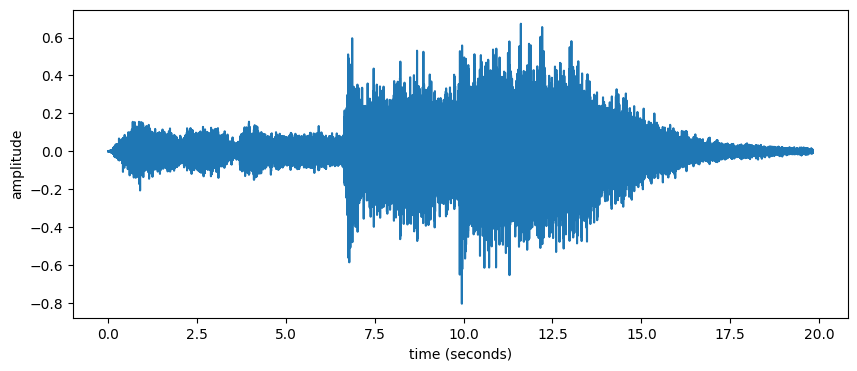

In [45]:
# Read training data

# set the batch size for training
batch=1

# load the audio file
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")

# convert the audio signal to PyTorch format
X_train = signal2pytorch(audio1).to(device)

# display training sound
display_sound(audio1, samplerate)

In [46]:
# Train model 

# create instance of model
model = Convautoenc().to(device)
print('Total number of parameters: %i' % (sum(p.numel() for p in model.parameters() if p.requires_grad)))
# loss function used is Mean Square Error
loss_fn = nn.MSELoss()
# generate initial predictions for the training data
Ypred = model(X_train)
#length of the signal at the output of the network
outputlen = len(Ypred[0,0,:])
print("outputlen=", outputlen)
#the target signal with same length as model output
Y=X_train[:,:,:outputlen]

# define the size of each update step and initialize the optimizer
learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# train the model over a number of epochs
nepochs = 500
for epoch in range(nepochs):
  # generates predictions for the current epoch
  Ypred = model(X_train)
  # computes the error between the predicted output and the target output
  loss = loss_fn(Ypred, Y)
  # prints the loss every 50 epochs
  if epoch%50==0:
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.4f}")
  # Resets the gradients of all model parameters to zero before backpropagation
  optimizer.zero_grad()
  # Computes gradients of the loss with respect to model parameters via backpropagation
  loss.backward()
  # Updates model parameters based on gradients calculated
  optimizer.step()

Total number of parameters: 262209
outputlen= 873474
Epoch [0/500], Loss: 0.0102
Epoch [50/500], Loss: 0.0020
Epoch [100/500], Loss: 0.0010
Epoch [150/500], Loss: 0.0007
Epoch [200/500], Loss: 0.0005
Epoch [250/500], Loss: 0.0004
Epoch [300/500], Loss: 0.0004
Epoch [350/500], Loss: 0.0003
Epoch [400/500], Loss: 0.0003
Epoch [450/500], Loss: 0.0003


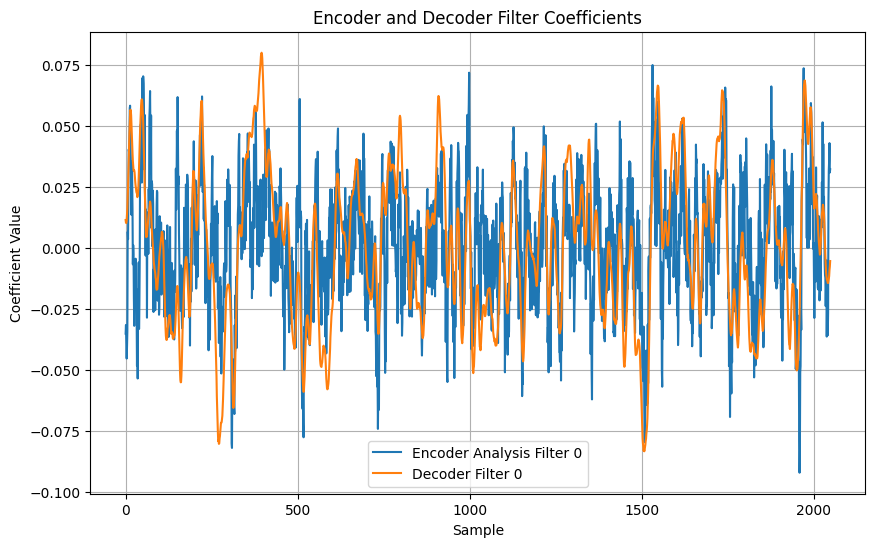

Number of input signal values: 874006
Number of elements in encoded signal: 54656


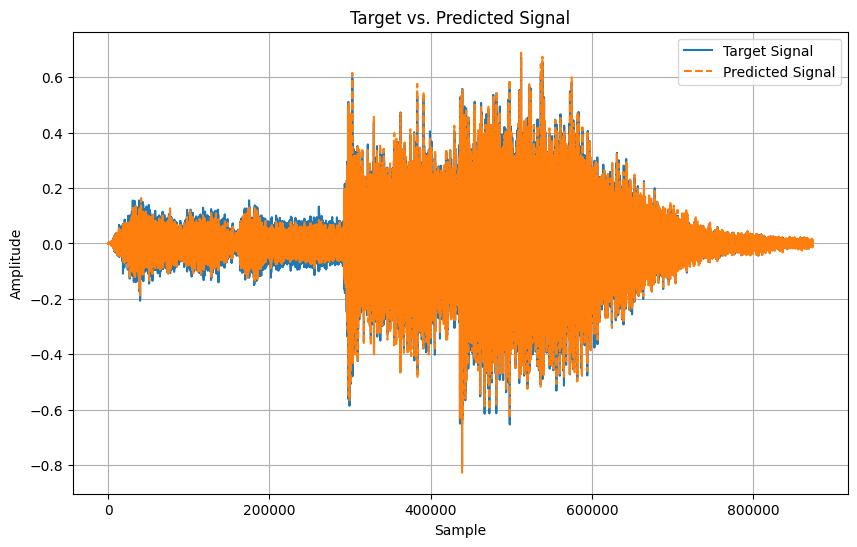

In [47]:
# Make model predictions using the training data

# Read and extract model weights
weights = model.state_dict()

# Convert the weights directly to NumPy arrays and transpose for plotting
encoder_weights = weights['conv1.weight'][0, 0, :].numpy().T
decoder_weights = weights['t_conv1.weight'][0, 0, :].numpy().T

# Plot obtained weights for encoder and decoder
plt.figure(figsize=(10, 6))
plt.plot(encoder_weights, label='Encoder Analysis Filter 0')
plt.plot(decoder_weights, label='Decoder Filter 0')
plt.xlabel('Sample')
plt.ylabel('Coefficient Value')
plt.title('Encoder and Decoder Filter Coefficients')
plt.legend()
plt.grid()
plt.show()

# Encode and decode to get predictions
encoded_signal = model.encoder(X_train)
print(f"Number of input signal values: {X_train.numel()}")
print(f"Number of elements in encoded signal: {encoded_signal.numel()}")

predictions = model.decoder(encoded_signal).detach().cpu().numpy()  # Convert to NumPy after detaching
target = Y.cpu().numpy()  # Convert target to NumPy for plotting

# Plot target signal and model predictions for comparison
plt.figure(figsize=(10, 6))
plt.plot(target[0, 0, :], label='Target Signal')
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.title('Target vs. Predicted Signal')
plt.legend()
plt.grid()
plt.show()

# Prepare reconstructed signal for playback (remove unnecessary dimensions)
reconstructed_signal = predictions[0, 0, :]

In [48]:
# play input and predicted sounds
display(ipd.Audio(audio1, rate=samplerate))
display(ipd.Audio(reconstructed_signal, rate=samplerate))

<font color=red> ***MY MODIFIED CODE*** </font>

Reduced Kernel

In [49]:
class Convautoenc(nn.Module):
    def __init__(self):
        super(Convautoenc, self).__init__()

        #reducing kernel size
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=1024, stride=1024, padding=1023, bias=True)
        self.t_conv1 = nn.ConvTranspose1d(in_channels=64, out_channels=1, kernel_size=1024, stride=1024, padding=1023, bias=True)

    def encoder(self, x):
        z = F.relu(self.conv1(x))
        return  z # Encoded features (latent representation)

    def decoder(self, z):
        x = self.t_conv1(z)
        return x  # Reconstructed signal

    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder(z)

        return y  # Final output, reconstructed signal


Total number of parameters: 131137
Epoch [0/500], Loss: 0.0098
Epoch [50/500], Loss: 0.0028
Epoch [100/500], Loss: 0.0014
Epoch [150/500], Loss: 0.0010
Epoch [200/500], Loss: 0.0008
Epoch [250/500], Loss: 0.0006
Epoch [300/500], Loss: 0.0005
Epoch [350/500], Loss: 0.0005
Epoch [400/500], Loss: 0.0004
Epoch [450/500], Loss: 0.0003
Number of input signal values: 874006
Number of elements in encoded signal for kernel size 1024 and stride 1024: 54720


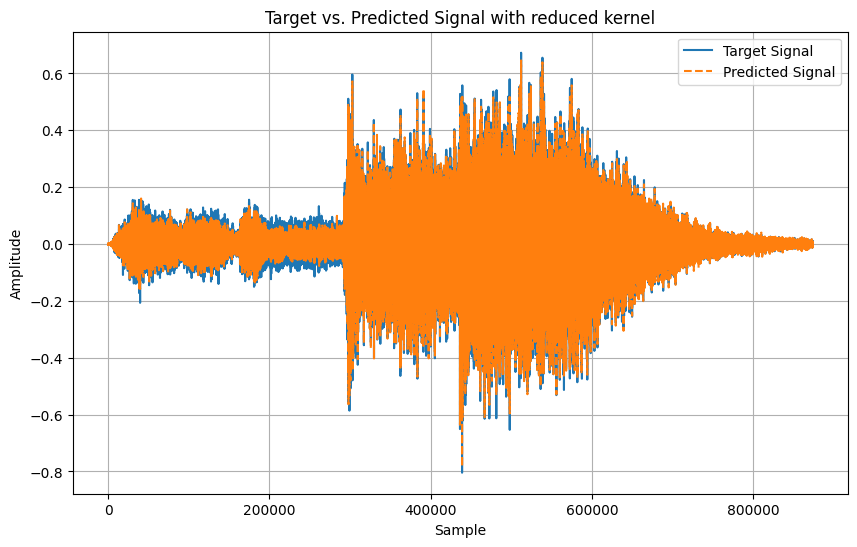

In [50]:
## EXPLORING IMPACT OF KERNEL SIZE AND STRIDE PARAMETERS
#### FOR REDUCED KERNEL
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)
print('Total number of parameters: %i' % (sum(p.numel() for p in model.parameters() if p.requires_grad)))

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

nepochs = 500
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%50==0:
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.4f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

#Step 03: Make Model Predictions
# Read and extract model weights
weights = model.state_dict()

# Convert the weights directly to NumPy arrays and transpose for plotting
encoder_weights = weights['conv1.weight'][0, 0, :].numpy().T
decoder_weights = weights['t_conv1.weight'][0, 0, :].numpy().T

# Encode and decode to get predictions
encoded_signal = model.encoder(X_train)

print(f"Number of input signal values: {X_train.numel()}")
print(f"Number of elements in encoded signal for kernel size 1024 and stride 1024: {encoded_signal.numel()}")


predictions = model.decoder(encoded_signal).detach().cpu().numpy()  # Convert to NumPy after detaching
target = Y.cpu().numpy()  # Convert target to NumPy for plotting

# Plot target signal and model predictions for comparison
plt.figure(figsize=(10, 6))
plt.plot(target[0, 0, :], label='Target Signal')
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.title('Target vs. Predicted Signal with reduced kernel')
plt.legend()
plt.grid()
plt.show()

reconstructed_signal = predictions[0, 0, :]

# Step 04: Play signal
# play input and predicted sounds
display(ipd.Audio(audio1, rate=samplerate))
display(ipd.Audio(reconstructed_signal, rate=samplerate))



Reduced Stride

In [51]:
class Convautoenc(nn.Module):
    def __init__(self):
        super(Convautoenc, self).__init__()

        #reducing stride
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=2048, stride=512, padding=1023, bias=True)
        self.t_conv1 = nn.ConvTranspose1d(in_channels=64, out_channels=1, kernel_size=2048, stride=512, padding=1023, bias=True)

    def encoder(self, x):
        z = F.relu(self.conv1(x))
        return  z # Encoded features (latent representation)

    def decoder(self, z):
        x = self.t_conv1(z)
        return x  # Reconstructed signal

    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder(z)

        return y  # Final output, reconstructed signal

Total number of parameters: 262209
Epoch [0/500], Loss: 0.0099
Epoch [50/500], Loss: 0.0015
Epoch [100/500], Loss: 0.0007
Epoch [150/500], Loss: 0.0005
Epoch [200/500], Loss: 0.0003
Epoch [250/500], Loss: 0.0003
Epoch [300/500], Loss: 0.0002
Epoch [350/500], Loss: 0.0002
Epoch [400/500], Loss: 0.0001
Epoch [450/500], Loss: 0.0001
Number of input signal values: 874006
Number of elements in encoded signal for kernel size 2048 and stride 512: 109312


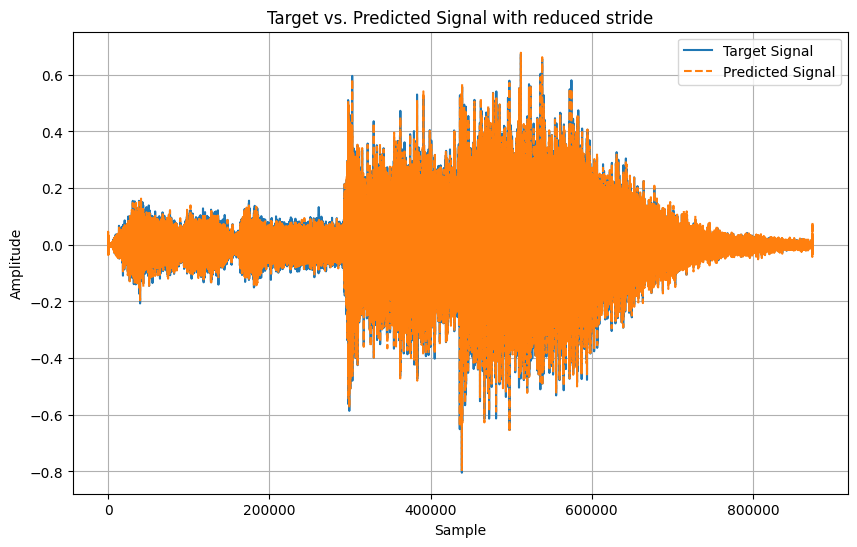

In [52]:
## EXPLORING IMPACT OF KERNEL SIZE AND STRIDE PARAMETERS
#### FOR REDUCED STRIDE
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)
print('Total number of parameters: %i' % (sum(p.numel() for p in model.parameters() if p.requires_grad)))

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

nepochs = 500
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%50==0:
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.4f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

#Step 03: Make Model Predictions
# Read and extract model weights
weights = model.state_dict()

# Convert the weights directly to NumPy arrays and transpose for plotting
encoder_weights = weights['conv1.weight'][0, 0, :].numpy().T
decoder_weights = weights['t_conv1.weight'][0, 0, :].numpy().T

# Encode and decode to get predictions
encoded_signal = model.encoder(X_train)

print(f"Number of input signal values: {X_train.numel()}")
print(f"Number of elements in encoded signal for kernel size 2048 and stride 512: {encoded_signal.numel()}")


predictions = model.decoder(encoded_signal).detach().cpu().numpy()  # Convert to NumPy after detaching
target = Y.cpu().numpy()  # Convert target to NumPy for plotting

# Plot target signal and model predictions for comparison
plt.figure(figsize=(10, 6))
plt.plot(target[0, 0, :], label='Target Signal')
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.title('Target vs. Predicted Signal with reduced stride')
plt.legend()
plt.grid()
plt.show()

reconstructed_signal = predictions[0, 0, :]

# Step 04: Play signal
# play input and predicted sounds
display(ipd.Audio(audio1, rate=samplerate))
display(ipd.Audio(reconstructed_signal, rate=samplerate))

Increased kernel

In [53]:
class Convautoenc(nn.Module):
    def __init__(self):
        super(Convautoenc, self).__init__()

        #increasing kernel size
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=4096, stride=1024, padding=1023, bias=True)
        self.t_conv1 = nn.ConvTranspose1d(in_channels=64, out_channels=1, kernel_size=4096, stride=1024, padding=1023, bias=True)

    def encoder(self, x):
        z = F.relu(self.conv1(x))
        return  z # Encoded features (latent representation)

    def decoder(self, z):
        x = self.t_conv1(z)
        return x  # Reconstructed signal

    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder(z)

        return y  # Final output, reconstructed signal

Total number of parameters: 524353
Epoch [0/500], Loss: 0.0098
Epoch [50/500], Loss: 0.0014
Epoch [100/500], Loss: 0.0006
Epoch [150/500], Loss: 0.0004
Epoch [200/500], Loss: 0.0003
Epoch [250/500], Loss: 0.0002
Epoch [300/500], Loss: 0.0002
Epoch [350/500], Loss: 0.0002
Epoch [400/500], Loss: 0.0002
Epoch [450/500], Loss: 0.0001
Number of input signal values: 874006
Number of elements in encoded signal for kernel size 4096 and stride 1024: 54528


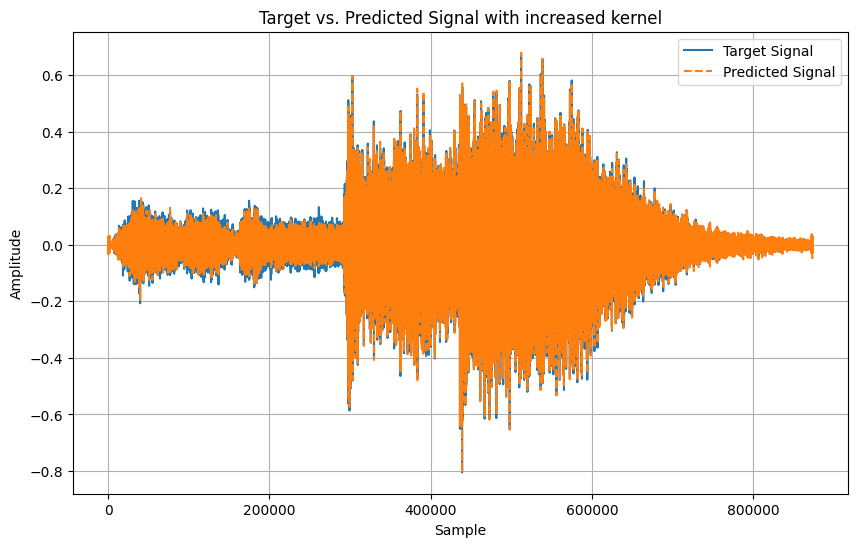

In [54]:
## EXPLORING IMPACT OF KERNEL SIZE AND STRIDE PARAMETERS
#### FOR INCRREASED KERNEL
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)
print('Total number of parameters: %i' % (sum(p.numel() for p in model.parameters() if p.requires_grad)))

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

nepochs = 500
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%50==0:
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.4f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

#Step 03: Make Model Predictions
# Read and extract model weights
weights = model.state_dict()

# Convert the weights directly to NumPy arrays and transpose for plotting
encoder_weights = weights['conv1.weight'][0, 0, :].numpy().T
decoder_weights = weights['t_conv1.weight'][0, 0, :].numpy().T

# Encode and decode to get predictions
encoded_signal = model.encoder(X_train)

print(f"Number of input signal values: {X_train.numel()}")
print(f"Number of elements in encoded signal for kernel size 4096 and stride 1024: {encoded_signal.numel()}")


predictions = model.decoder(encoded_signal).detach().cpu().numpy()  # Convert to NumPy after detaching
target = Y.cpu().numpy()  # Convert target to NumPy for plotting

# Plot target signal and model predictions for comparison
plt.figure(figsize=(10, 6))
plt.plot(target[0, 0, :], label='Target Signal')
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.title('Target vs. Predicted Signal with increased kernel')
plt.legend()
plt.grid()
plt.show()

reconstructed_signal = predictions[0, 0, :]

# Step 04: Play signal
# play input and predicted sounds
display(ipd.Audio(audio1, rate=samplerate))
display(ipd.Audio(reconstructed_signal, rate=samplerate))

Increased Stride

In [55]:
class Convautoenc(nn.Module):
    def __init__(self):
        super(Convautoenc, self).__init__()

        #increasing stride
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=2048, stride=2048, padding=1023, bias=True)
        self.t_conv1 = nn.ConvTranspose1d(in_channels=64, out_channels=1, kernel_size=2048, stride=2048, padding=1023, bias=True)

    def encoder(self, x):
        z = F.relu(self.conv1(x))
        return  z # Encoded features (latent representation)

    def decoder(self, z):
        x = self.t_conv1(z)
        return x  # Reconstructed signal

    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder(z)

        return y  # Final output, reconstructed signal

Total number of parameters: 262209
Epoch [0/500], Loss: 0.0101
Epoch [50/500], Loss: 0.0026
Epoch [100/500], Loss: 0.0013
Epoch [150/500], Loss: 0.0009
Epoch [200/500], Loss: 0.0008
Epoch [250/500], Loss: 0.0007
Epoch [300/500], Loss: 0.0006
Epoch [350/500], Loss: 0.0006
Epoch [400/500], Loss: 0.0006
Epoch [450/500], Loss: 0.0006
Number of input signal values: 874006
Number of elements in encoded signal for kernel size 2048 and stride 2048: 27328


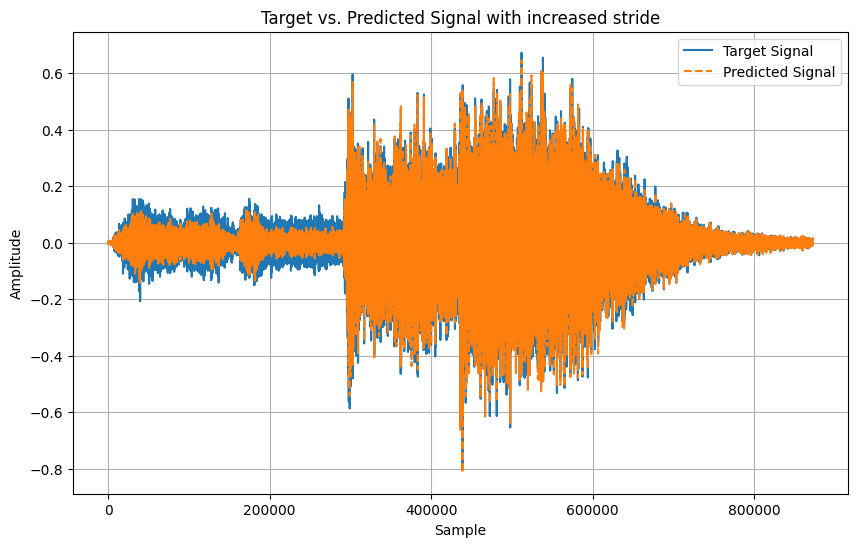

In [56]:
## EXPLORING IMPACT OF KERNEL SIZE AND STRIDE PARAMETERS
#### FOR INCREASED STRIDE
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)
print('Total number of parameters: %i' % (sum(p.numel() for p in model.parameters() if p.requires_grad)))

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

nepochs = 500
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%50==0:
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.4f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

#Step 03: Make Model Predictions
# Read and extract model weights
weights = model.state_dict()

# Convert the weights directly to NumPy arrays and transpose for plotting
encoder_weights = weights['conv1.weight'][0, 0, :].numpy().T
decoder_weights = weights['t_conv1.weight'][0, 0, :].numpy().T

# Encode and decode to get predictions
encoded_signal = model.encoder(X_train)

print(f"Number of input signal values: {X_train.numel()}")
print(f"Number of elements in encoded signal for kernel size 2048 and stride 2048: {encoded_signal.numel()}")


predictions = model.decoder(encoded_signal).detach().cpu().numpy()  # Convert to NumPy after detaching
target = Y.cpu().numpy()  # Convert target to NumPy for plotting

# Plot target signal and model predictions for comparison
plt.figure(figsize=(10, 6))
plt.plot(target[0, 0, :], label='Target Signal')
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.title('Target vs. Predicted Signal with increased stride')
plt.legend()
plt.grid()
plt.show()

reconstructed_signal = predictions[0, 0, :]

# Step 04: Play signal
# play input and predicted sounds
display(ipd.Audio(audio1, rate=samplerate))
display(ipd.Audio(reconstructed_signal, rate=samplerate))

Increasing kernel and reducing stride

In [57]:
class Convautoenc(nn.Module):
    def __init__(self):
        super(Convautoenc, self).__init__()

        #increasing kernel and reducing stride
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=4096, stride=512, padding=1023, bias=True)
        self.t_conv1 = nn.ConvTranspose1d(in_channels=64, out_channels=1, kernel_size=4096, stride=512, padding=1023, bias=True)

    def encoder(self, x):
        z = F.relu(self.conv1(x))
        return  z # Encoded features (latent representation)

    def decoder(self, z):
        x = self.t_conv1(z)
        return x  # Reconstructed signal

    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder(z)

        return y  # Final output, reconstructed signal

Total number of parameters: 524353
Epoch [0/500], Loss: 0.0099
Epoch [50/500], Loss: 0.0011
Epoch [100/500], Loss: 0.0005
Epoch [150/500], Loss: 0.0003
Epoch [200/500], Loss: 0.0002
Epoch [250/500], Loss: 0.0002
Epoch [300/500], Loss: 0.0001
Epoch [350/500], Loss: 0.0001
Epoch [400/500], Loss: 0.0001
Epoch [450/500], Loss: 0.0001
Number of input signal values: 874006
Number of elements in encoded signal for kernel size 2048 and stride 2048: 109056


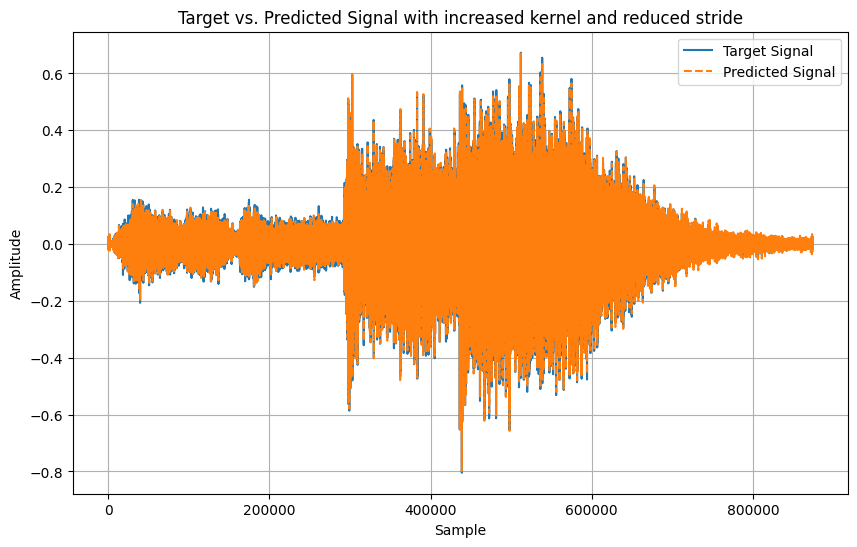

In [58]:
## EXPLORING IMPACT OF KERNEL SIZE AND STRIDE PARAMETERS
#### FOR INCREASED KERNEL AND REDUCED STRIDE
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)
print('Total number of parameters: %i' % (sum(p.numel() for p in model.parameters() if p.requires_grad)))

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

nepochs = 500
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%50==0:
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.4f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

#Step 03: Make Model Predictions
# Read and extract model weights
weights = model.state_dict()

# Convert the weights directly to NumPy arrays and transpose for plotting
encoder_weights = weights['conv1.weight'][0, 0, :].numpy().T
decoder_weights = weights['t_conv1.weight'][0, 0, :].numpy().T

# Encode and decode to get predictions
encoded_signal = model.encoder(X_train)

print(f"Number of input signal values: {X_train.numel()}")
print(f"Number of elements in encoded signal for kernel size 2048 and stride 2048: {encoded_signal.numel()}")


predictions = model.decoder(encoded_signal).detach().cpu().numpy()  # Convert to NumPy after detaching
target = Y.cpu().numpy()  # Convert target to NumPy for plotting

# Plot target signal and model predictions for comparison
plt.figure(figsize=(10, 6))
plt.plot(target[0, 0, :], label='Target Signal')
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.title('Target vs. Predicted Signal with increased kernel and reduced stride')
plt.legend()
plt.grid()
plt.show()

reconstructed_signal = predictions[0, 0, :]

# Step 04: Play signal
# play input and predicted sounds
display(ipd.Audio(audio1, rate=samplerate))
display(ipd.Audio(reconstructed_signal, rate=samplerate))

Question 3

In [59]:
# original class
class Convautoenc(nn.Module):
    def __init__(self):
        super(Convautoenc, self).__init__()

        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=2048, stride=1024, padding=1023, bias=True)
        self.t_conv1 = nn.ConvTranspose1d(in_channels=64, out_channels=1, kernel_size=2048, stride=1024, padding=1023, bias=True)

    def encoder(self, x):
        z = F.relu(self.conv1(x))
        return  z # Encoded features (latent representation)

    def decoder(self, z):
        x = self.t_conv1(z)
        return x  # Reconstructed signal

    def forward(self, x):
        z = self.encoder(x)
        y = self.decoder(z)

        return y  # Final output, reconstructed signal


In [60]:
## MODIFY NUMBER OF EPOCHS or LEARNING RATE TO IMPROVE RECONSTRUCTION QUALITY
## INCREASING EPOCH
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
print("2000 EPOCHS, 1e-3 LEARNING STEP")
nepochs = 2001
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%400==0:                                                       
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.6f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

2000 EPOCHS, 1e-3 LEARNING STEP
Epoch [0/2001], Loss: 0.010220
Epoch [400/2001], Loss: 0.000275
Epoch [800/2001], Loss: 0.000156
Epoch [1200/2001], Loss: 0.000138
Epoch [1600/2001], Loss: 0.000128
Epoch [2000/2001], Loss: 0.000124


In [61]:

## MODIFY NUMBER OF EPOCHS or LEARNING RATE TO IMPROVE RECONSTRUCTION QUALITY
## DECREASING EPOCHSS
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

print("100 EPOCHS, 1e-3 LEARNING STEP")
nepochs = 101
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%20==0:                
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.6f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

100 EPOCHS, 1e-3 LEARNING STEP
Epoch [0/101], Loss: 0.009842
Epoch [20/101], Loss: 0.003884
Epoch [40/101], Loss: 0.002500
Epoch [60/101], Loss: 0.001654
Epoch [80/101], Loss: 0.001210
Epoch [100/101], Loss: 0.000963


In [62]:

## MODIFY NUMBER OF EPOCHS or LEARNING RATE TO IMPROVE RECONSTRUCTION QUALITY
## decreasing learning step
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)
loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-4
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

print("500 EPOCHS, 1e-4 LEARNING STEP")
nepochs = 501
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%100==0:               
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.6f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

500 EPOCHS, 1e-4 LEARNING STEP
Epoch [0/501], Loss: 0.010018
Epoch [100/501], Loss: 0.004080
Epoch [200/501], Loss: 0.002873
Epoch [300/501], Loss: 0.001960
Epoch [400/501], Loss: 0.001446
Epoch [500/501], Loss: 0.001155


In [63]:

## MODIFY NUMBER OF EPOCHS or LEARNING RATE TO IMPROVE RECONSTRUCTION QUALITY
## increasing learning step
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 1e-2
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

print("500 EPOCHS, 1e-2 LEARNING STEP")
nepochs = 501
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%100==0:               
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.6f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

500 EPOCHS, 1e-2 LEARNING STEP
Epoch [0/501], Loss: 0.010055
Epoch [100/501], Loss: 0.000753
Epoch [200/501], Loss: 0.000473
Epoch [300/501], Loss: 0.000611
Epoch [400/501], Loss: 0.000408
Epoch [500/501], Loss: 0.000337


In [64]:
## MODIFY NUMBER OF EPOCHS or LEARNING RATE TO IMPROVE RECONSTRUCTION QUALITY
## increasing epochs and learning step
# Step 01: Read Training Data
batch=1
audio1, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-1.wav")
X_train = signal2pytorch(audio1).to(device)

# Step 02: Train model
model = Convautoenc().to(device)

loss_fn = nn.MSELoss()

Ypred = model(X_train)

outputlen = len(Ypred[0,0,:])
Y=X_train[:,:,:outputlen]

learning_rate = 5e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

print("1000 EPOCHS, 5e-3 LEARNING STEP")
nepochs = 1001
for epoch in range(nepochs):
  Ypred = model(X_train)
  loss = loss_fn(Ypred, Y)
  if epoch%200==0:               
    print(f"Epoch [{epoch}/{nepochs}], Loss: {loss.item():.6f}")
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()


1000 EPOCHS, 5e-3 LEARNING STEP
Epoch [0/1001], Loss: 0.010076
Epoch [200/1001], Loss: 0.000304
Epoch [400/1001], Loss: 0.000223
Epoch [600/1001], Loss: 0.000171
Epoch [800/1001], Loss: 0.000174
Epoch [1000/1001], Loss: 0.000239


**Questions:**

1. Explore the impact of kernel_size and stride parameters. Change the size of these parameters and explain its effect in the quality of the reconstruction and the size of the encoded signal.

    <font color=red> To correctly analyze the impact of the kernel size and the stride parameters I have done 5 different cases:
    - Decreasing the kernel size
    - Decreasing the stride
    - Increasing the kernel size
    - Increasing the stride
    - Increasing the kernel size and decreasing the stride
    
    The perceptual differences between one reconstruction and another were very noticeable in all the cases. 
    - The worst recostruction was when we increased by 2 the stride. The model had the highest Loss error, (0.0005) and on the superposition of the original and reconstructed waveform we could see how much different they were. 
    
    Since the stride controls how much the kernel moves (or slides) in a direction, it makes sense that the greater there is, the workse the reconstruction, since the more it slides and the more information we lose. 
    
    - The next worst one was when we decreased by 2 the kernel size. The model had a Loss error of 0.0003, and altough the difference on the superposition of the original and reconstructed waveform was not as exaggerated as the previous case, on the recostructed audio we heard a lot of noise, both static and "silences".
    
    Since the kernel is the number of filters you use, it also makes sense that the less filters, the more different the approximation of the signal is to the original signal, therefore, losing information again.

    - Then we had the incrementation by 2 of the kernel size. In this case the model had a Loss error of 0.0001, the original and reconstructed waveform was very similar, but we still hear a bit of "static" noise.

    - And the best one was when we decreased by 2 the stride. The model also had a Loss error of 0.0001, . In this case the difference between original and reconstructed waveform is minimal, and the audio sounds good. There is background noise, and it is not as rich as it should be (some higer frequencies are missing), it is the best reconstruction.

    So, knowing that the higher the kernel and the lower the stride, the better the resolution, we did a case when we increased and decreased by 2, respectively. However, there was not much difference between this case and the case where we only reduced the stride.
    This makes sense because the number of elements in the encoded signal was very similar for both cases (109056 vs 109312), whereas in the example of the reduction of kernel it goes to 54729, and in the incrementation of the stride we had 27328.

    In addition, the training of the model was very slow, so for the little difference that there is, I believe that it would be best to stay only with the decreased stride case.
    </font>

2. Increase the compression rate by introducing more convolutional layers in both encoder and decoder (check convolutional_autoencoder_complex.ipynb example). What is the tradeoff of doing this? Document your observations.

<font color=red> The more convolutional layers the model has, the more compression it will achieve.

The encoder is a series of convolutional layers that compresses the input audio into a lower-dimensional representation. 

These convolutional layers learn to extract important features like the harmonics or the transients while reducing redundancy.
Each feature map highlights a specific pattern, and multiple CNNs can be stacked to capture progressively more complex patterns.
The final output of the encoder is a bottleneck, that is, a highly compressed version of the input. 

The more convolutional layers the encoder has, the smaller the bottleneck will be, since at every layer it is extracting information but reducing redundancy, meaning that there is a risk of losing important audio details, and the more convolutional layers we have, the greater the risk.
In addition, the more convolutional layers, the slower the model will be, so we must also take into account the cost of time and power/computation.

The decoder is the inverse of the encoder, it is a series of transposed CNNs that upsample the compressed data to reconstruct the original audio. Its goal is to reconstruct it as accurately as possible from the compressed representation, meaning that the success of the decoder depends on how well the encoder captured the essential features of the audio.

So, we must take into account the type of signal that we have, the more complex the signal, the more convolutional layer sthat we might need to make a correct approximation. However, for simple signals it may result in ignoring important information and reducing the quality of the reconstruction. Increasing the number of convolutional layers will result in a higher compression, but at the cost of audio quality. The key is to find the right balance between copression rate and audio quality.  </font>

3. Get a better reconstruction quality by modifying the number of epochs and / or learning rate. What are the optimal numbers? How does the number of epochs and learning rate affect the model's performance? What is the impact of training for too few or too many epochs?

    <font color=red> For this question I have not computed the reconstructed waveform, I only focused on the loss error of the model. Just like on question 1, I have done 5 cases: 
    - Increasing the number of epochs
    - Decreasing the number of epochs
    - Increasing the learning step
    - Decreasing the learning step
    And very similar to question 1 too, the greater the number of epochs, the better, and the smaller the learning step the better too. However, there is a limit of how much epochs and how small the learning step, because there can be a lot of problems if chosen wrong.
    
    The number of epochs is the number of complete passes trhoruhg the entire training dataset. It is the same as an iteration, except that, for every iteration, the weighs get updated in a way that they will optimize the result.
    
    Therefore, it makes sense that the more iterations, the better the weights will be. However, there is a limit where they will not be optimized anymore. That is why for example in or 2000 epochs case we get almost the same result as in our 1000 epochs case.
    
    Then, the learning step is important to compute correctly.It is the setp size between samples on the optimizing function, which in our case is a gradient descent. 
    If we pick a learning gradient that is too small, we risk not arriving to the lowest point (the most optimized value) in the number of epochs that we pick. 
    However, if we pick a learning gradient that is too large, we risk skipping it over and over again.
    In our case, both 1e-4 and 1e-2 are too small and too large, that is why the Loss error is very high on both cases, it has not reached the peak.
    
    So we did a new case, with the number of epochs set at 1000 and the learning step at 5e-3, which have us the 2nd best result, 0.00015 but it took half the time than the best result of all, which was with 2000 epochs and the learning step at 1e-3, and 0.00012, which is a difference of 3 at the 5th decimal, meaning, not significative. </font>

    ** Values might not be the same after re-running.
____

## Part 2 - Generalization of model

Explore the generalization quality of the model trained on a single sound.

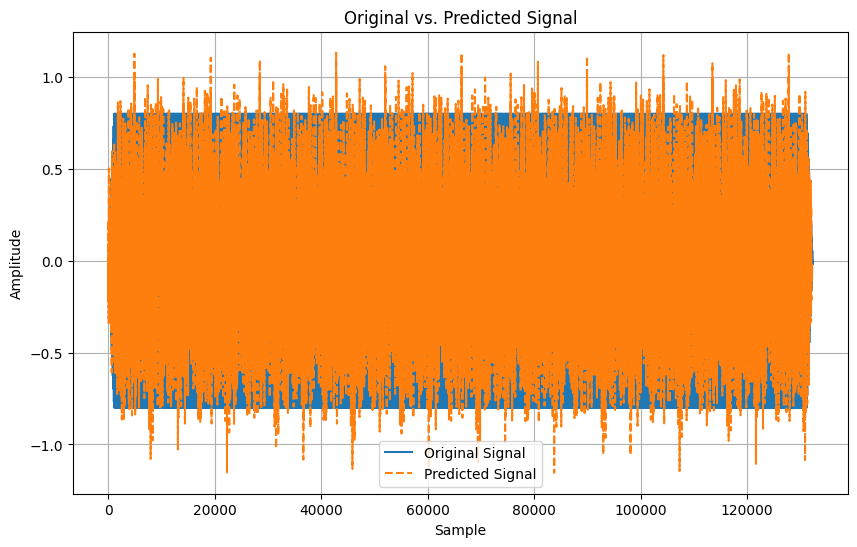

In [65]:
# Encode/decode on signal different from the one used for training

# audio2, samplerate = read_sound("../sounds/162095-chinese-orchestra-channel-2.wav")
audio2, samplerate = read_sound("../sounds/sinewave.wav")
#Convert to pytorch format, batch is first dimension
X_test = signal2pytorch(audio2).to(device) 

# Make Predictions based on the obtained weights
predictions = model(X_test).detach().cpu().numpy()  # Ensure predictions are detached and on CPU

# Plot the original test signal and the model's predicted reconstruction
plt.figure(figsize=(10, 6))
plt.plot(X_test[0, 0, :].detach().cpu().numpy(), label='Original Signal')  # Original test signal, detached
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Predicted Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

# Prepare reconstructed signal for playback (remove unnecessary dimensions)
reconstructed_signal = predictions[0, 0, :]

In [66]:
# play input and predicted sound
display(ipd.Audio(audio2, rate=samplerate))
display(ipd.Audio(reconstructed_signal, rate=samplerate))

<font color=red> ***MY MODIFIED CODE*** </font>

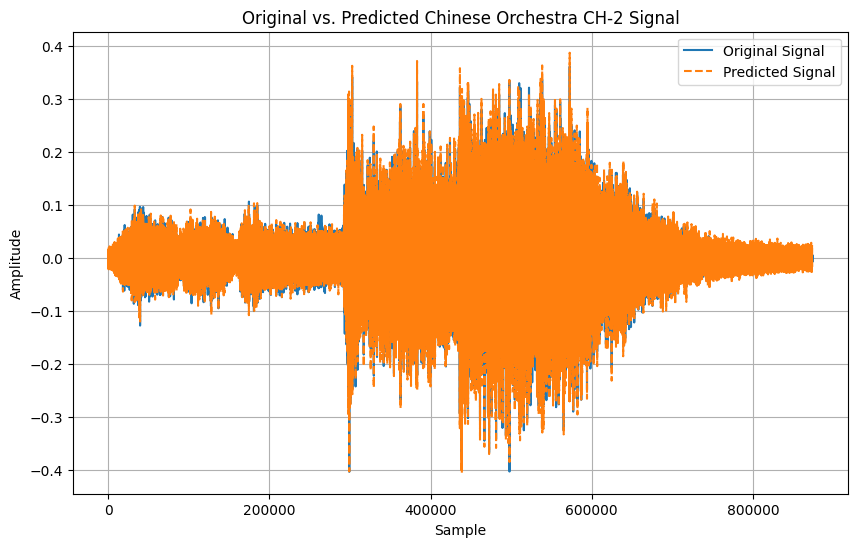

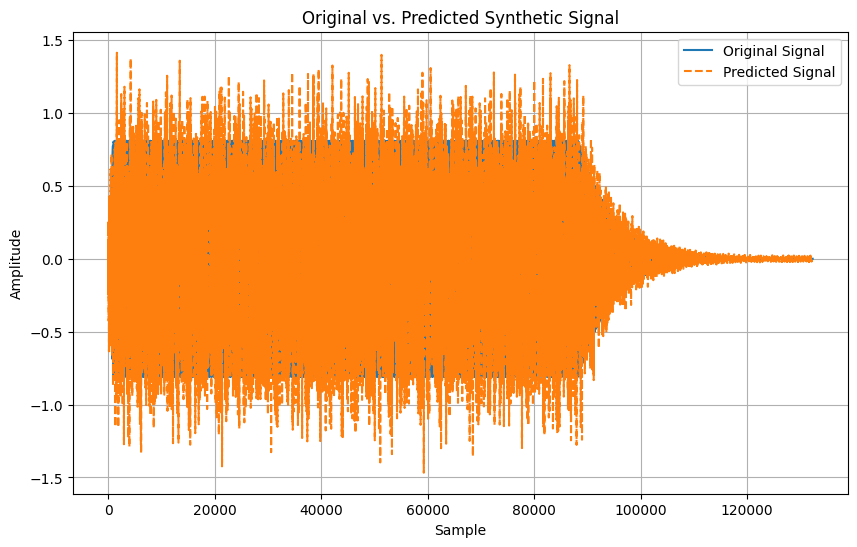

In [67]:
## TRYING MODEL ON OTHER SOUNDS: CHINESE CHANNEL 2 + SYNTHETIC

## chinese
chinese2, samplerate_c = read_sound("../sounds/162095-chinese-orchestra-channel-2.wav")
X_test = signal2pytorch(chinese2).to(device) 

# Make Predictions based on the obtained weights
predictions = model(X_test).detach().cpu().numpy()  # Ensure predictions are detached and on CPU

# Plot the original test signal and the model's predicted reconstruction
plt.figure(figsize=(10, 6))
plt.plot(X_test[0, 0, :].detach().cpu().numpy(), label='Original Signal')  # Original test signal, detached
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Predicted Chinese Orchestra CH-2 Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

# Prepare reconstructed signal for playback (remove unnecessary dimensions)
reconstructed_signal = predictions[0, 0, :]

# Play input and predicted sound
display(ipd.Audio(chinese2, rate=samplerate_c))
display(ipd.Audio(reconstructed_signal, rate=samplerate_c))




## synthetic
synthetic, samplerate_s = read_sound("../sounds/synthetic.wav")
X_test = signal2pytorch(synthetic).to(device) 

# Make Predictions based on the obtained weights
predictions = model(X_test).detach().cpu().numpy()  # Ensure predictions are detached and on CPU

# Plot the original test signal and the model's predicted reconstruction
plt.figure(figsize=(10, 6))
plt.plot(X_test[0, 0, :].detach().cpu().numpy(), label='Original Signal')  # Original test signal, detached
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Predicted Synthetic Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

# Prepare reconstructed signal for playback (remove unnecessary dimensions)
reconstructed_signal = predictions[0, 0, :]

# Play input and predicted sound
display(ipd.Audio(synthetic, rate=samplerate_s))
display(ipd.Audio(reconstructed_signal, rate=samplerate_s))

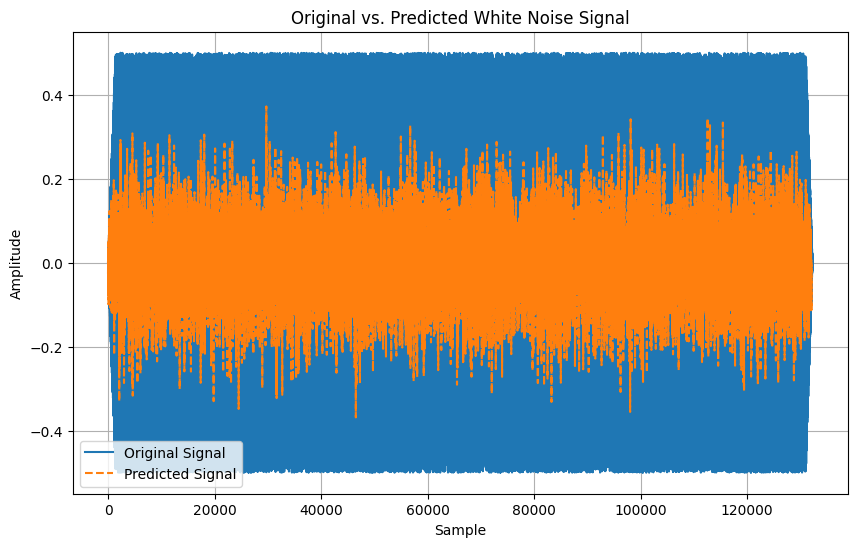

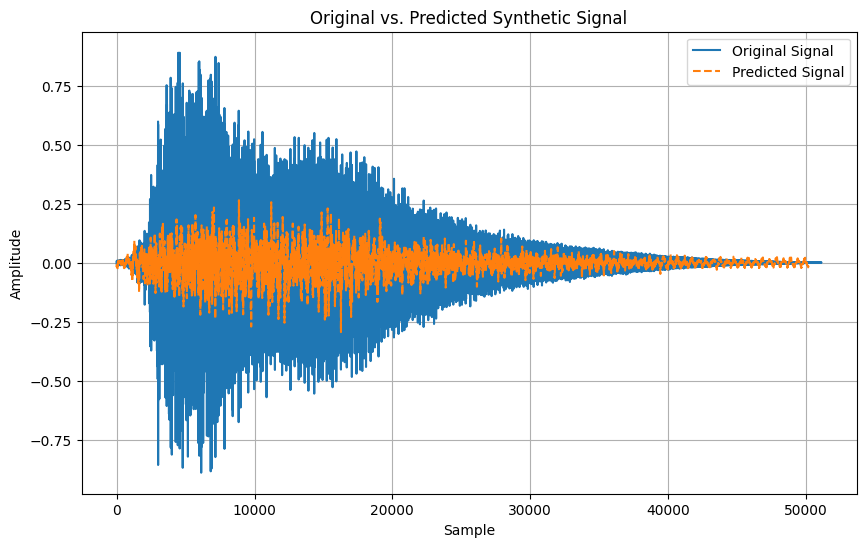

C:\Users\laiap\AppData\Local\Temp\ipykernel_12420\2378861729.py:11: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sampling_rate, x = read(file)
c:\Users\laiap\Documents\GitHub\audio-coding-materials\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


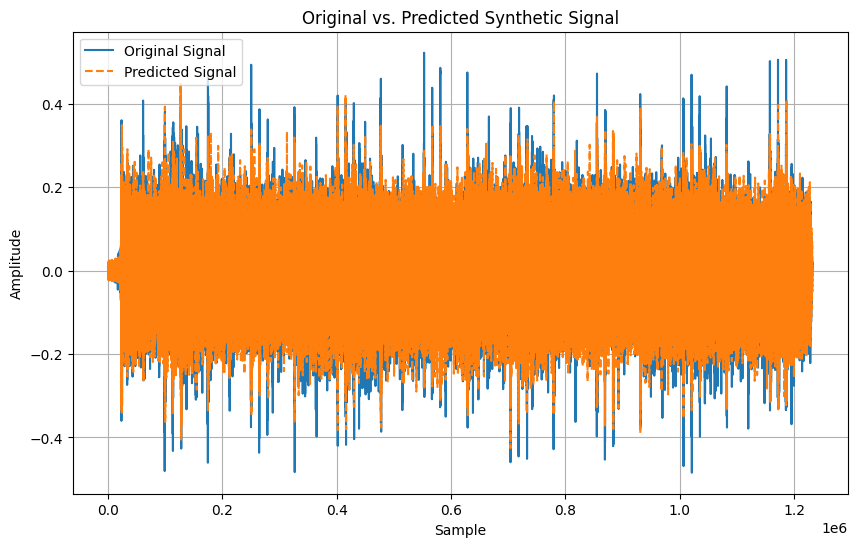

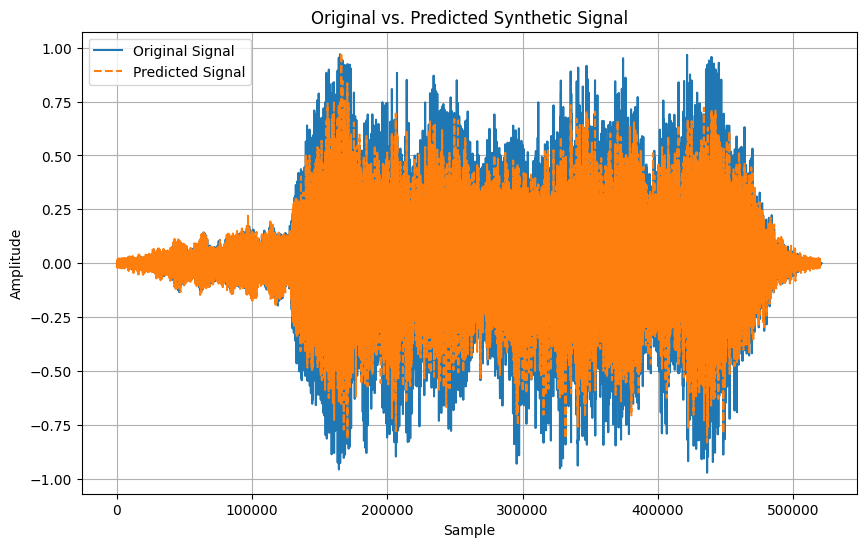

In [68]:
## EVALUATING FOR VERY DIFFERENT SOUNDS: White Noise, Sword Shing, Background Music.

## white-noise
whitenoise, samplerate_wh = read_sound("../sounds/white-noise.wav")
X_test = signal2pytorch(whitenoise).to(device) 

# Make Predictions based on the obtained weights
predictions = model(X_test).detach().cpu().numpy()  # Ensure predictions are detached and on CPU

# Plot the original test signal and the model's predicted reconstruction
plt.figure(figsize=(10, 6))
plt.plot(X_test[0, 0, :].detach().cpu().numpy(), label='Original Signal')  # Original test signal, detached
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Predicted White Noise Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

# Prepare reconstructed signal for playback (remove unnecessary dimensions)
reconstructed_signal = predictions[0, 0, :]

# Play input and predicted sound
display(ipd.Audio(whitenoise, rate=samplerate_wh))
display(ipd.Audio(reconstructed_signal, rate=samplerate_wh))




## sword shing
sword, samplerate_sw = read_sound("../sounds/718782-sword-shing.wav")
X_test = signal2pytorch(sword).to(device) 

# Make Predictions based on the obtained weights
predictions = model(X_test).detach().cpu().numpy()  # Ensure predictions are detached and on CPU

# Plot the original test signal and the model's predicted reconstruction
plt.figure(figsize=(10, 6))
plt.plot(X_test[0, 0, :].detach().cpu().numpy(), label='Original Signal')  # Original test signal, detached
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Predicted Synthetic Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

# Prepare reconstructed signal for playback (remove unnecessary dimensions)
reconstructed_signal = predictions[0, 0, :]

# Play input and predicted sound
display(ipd.Audio(sword, rate=samplerate_sw))
display(ipd.Audio(reconstructed_signal, rate=samplerate_sw))




## bg music
bgmusic, samplerate_bg = read_sound("../sounds/750340-background-music.wav")
X_test = signal2pytorch(bgmusic).to(device) 

# Make Predictions based on the obtained weights
predictions = model(X_test).detach().cpu().numpy()  # Ensure predictions are detached and on CPU

# Plot the original test signal and the model's predicted reconstruction
plt.figure(figsize=(10, 6))
plt.plot(X_test[0, 0, :].detach().cpu().numpy(), label='Original Signal')  # Original test signal, detached
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Predicted Synthetic Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

# Prepare reconstructed signal for playback (remove unnecessary dimensions)
reconstructed_signal = predictions[0, 0, :]

# Play input and predicted sound
display(ipd.Audio(bgmusic, rate=samplerate_bg))
display(ipd.Audio(reconstructed_signal, rate=samplerate_bg))


## fantasy orchestra
fantasy, samplerate_fo = read_sound("../sounds/348275-fantasy-orchestra.wav")
X_test = signal2pytorch(fantasy).to(device) 

# Make Predictions based on the obtained weights
predictions = model(X_test).detach().cpu().numpy()  # Ensure predictions are detached and on CPU

# Plot the original test signal and the model's predicted reconstruction
plt.figure(figsize=(10, 6))
plt.plot(X_test[0, 0, :].detach().cpu().numpy(), label='Original Signal')  # Original test signal, detached
plt.plot(predictions[0, 0, :], label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Predicted Synthetic Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

# Prepare reconstructed signal for playback (remove unnecessary dimensions)
reconstructed_signal = predictions[0, 0, :]

# Play input and predicted sound
display(ipd.Audio(fantasy, rate=samplerate_fo))
display(ipd.Audio(reconstructed_signal, rate=samplerate_fo))

**Questions:**

1. Evaluate generality of trained model by using other sounds. Try on the other channel of Chinese orchestra sound (162095-chinese-orchestra-channel-2.wav). How does it perform in comparison with the sound used for training? Explain your observations?

<font color=red> For this question I have used 2 signals: the Chinese Orchestra Channel 2 and the Synthetic.

On the case of the Chinese Orchestra CH-2, perceivably speaking the result is practically the same to the one from CH-1, that is, the signal that the model has been trained on. This is due to the fact that they are the same (perceivably speaking too), they have the same harmonics, the same transients, etc.
This results in a bad reconstruction, (due to the parameters used), but in a reconstruction that the original signal is recognized.

However, on the synthetic signal, that is extremely different, the reconstruction is very bad. OIt contains a lot of unwanted harmonics, static noise, silences... And on the waveforms superpositions we can see how the reconstructed signal is saturated, that is, its amplitude is much higher than it should be.

This makes sense, since different signals have different properties, therefore the model will consider important features in the signal trained that are not present (or important) in another signal.
Related to this, we can perceive how the reconstructec signal for the synthetic sound is more "musical" than the original. The fundamental frequency of this signal may be considered an important feature on the chinese orchestra signal, and therefore, when using that model to reconstruct the synthetic signal, that frequency gets more approximated to how it behaved on the chinese one.  </font>

2. Evaluate on a very different sound. Which are the ones for which the model performs poorly? Explain.

    <font color=red> This time I have chosen 4 other sounds: White Noise, Sword Shing, Background Music, and Fantasy Orchestra.
    
    Each sound is very different from the other, and at the same time, different with the trained sound. 
    - White Noise contains all frequencies at aproximately the same amplitude
    - Sword shing is very short, very high frequencied and with low amplitude
    - Background music is extremely complex, with a lot of low frequencies, and as the name says, musical.
    - Fantasy orchestra is another complex sound, it has both low and high frequencies, but as it is also an orchestra type of sound, it may have more similarities with the trained signal than the rest of the sounds.

    The first thing that I can see for the first 2 sounds is that the amplitude has been reduced almost by half, which is a lot. However, it more or less mantains the rythm/structure of the sound (when the amplitude decreases on the original it also decreases on the reconstructed).

    These 2 signals do not sound at all as they should be.
    - For the white noise signal, the low frequencies have been almost erradicated, the ones that we can hear most are in the middle and high range. In addition, it sounds as if every frequency had been "mapped" onto a piano key, and the white noise was someone randomly hitting keys at a very high speed. Just like it happened to the synthetic sound, this one is also kind of melodic/musical now. 

    - For the sword shing something similar happens, however, since the range of frequencies existing in that sound is much lower and the signal is much shorter and lower in amplitude, it does not sound so "random" and high. 

    Then we have the other 2 signals, background music and fantasy orchestra, which broadly speaking, may have more in common with the trained signal than the previous ones.
    We can see how this time the amplitude has been greatly mantained over time in both signals. In the case of background music there are some peaks that it does not "reconstruct", but on the fantasy orchestra until the 100000th sample both signals are almost the same. 

    Perceivably speaking there are more differences: None of them have been even slightly correctly reconstructed, but we can identify the original signal, which we could not do on the previous ones. 

    - For the background music we can perceive the bass hits and the rythm of the sound correctly, however the rest of the sound is more difficult to recognize. If we listen carefully, we can hear "on the background" the original signal, but it is being covered by the higher im amplitude frequencies from the model. We can say that some of the signal has been reconstructed correctly, however most of it has been approximated to how the chinese orchestra sounded. Instead of techno, we hear again this "random key hitting" from the "piano". 

    - For the fantasy orchestra we can actually hear almost perfectly the first 3 seconds of the signal. However, once it starts being more complex, that is, higher amplitude, more frequencies combined, and more high frequencies, the same as the background music occurs.
    The lower frequencies are mantained, since the chinese orchestra did not have much, but the higher frequencies are being approximated to how the higher frequencies sounded on that signal, therefore almost ignoring how they sound on this signal.

    With this we could say that the simplest the sound and the lowest range of frequencies that it has, the better reconstructed it will be. In addition, the more similar the sound is to the trained one, the better the reconstruction too.
     </font>

3. What could be done to improve the model generalization? (answer theoretically)
_______

## Part 3 - ENCODEC
Experiment with the Encodec neural codec.

In [69]:
from IPython.display import Audio
from transformers import AutoProcessor, EncodecModel
import torch
import torchaudio

# Load the pretrained processor and model
processor = AutoProcessor.from_pretrained("facebook/encodec_24khz")
encodec = EncodecModel.from_pretrained("facebook/encodec_24khz")

In [70]:
import soundfile as sf

In [71]:

torchaudio.set_audio_backend("soundfile")

C:\Users\laiap\AppData\Local\Temp\ipykernel_12420\187953065.py:1: UserWarning: torchaudio._backend.set_audio_backend has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for more information. It will be removed from the 2.9 release. 
  torchaudio.set_audio_backend("soundfile")


In [72]:
# load audio to encode
audio_path = "../sounds/721313-hangpan.wav"
# audio_path = '../sounds/synthetic.wav'
# audio_path = '../sounds/718782-sword-shing.wav'
# audio_path = '../sounds/632748-pavilion.wav'
# audio_path = '../sounds/263506-hallway.wav'

sample_rate = 24000

waveform, orig_sample_rate = torchaudio.load("../sounds/721313-hangpan.wav")
waveform = waveform[:1] # Load first channel of the audio
waveform = torchaudio.functional.resample(waveform, orig_freq=orig_sample_rate, new_freq=sample_rate).squeeze(0) # Resample the audio

# Preprocess the audio
inputs = processor(raw_audio=waveform, sampling_rate=sample_rate, return_tensors="pt")
bandwidths = encodec.config.target_bandwidths
print(f"Available bandwidths: {bandwidths} kbps")

# Encode the audio
target_bandwidth = bandwidths[-1] # highest bandwidth
# target_bandwidth = bandwidths[0] # lowest bandwidth
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)

codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales

# compute bandwith
import math

print(f"Target bandwidth: {target_bandwidth:.2f} kbps")
duration = waveform.shape[-1] / sample_rate
# latent codes per second
cps = codes.shape[-2] * codes.shape[-1] / duration
# bits per codebook
bpc = math.log2(encodec.config.codebook_size)
calculated_bandwidth = cps * bpc / 1000
print(f"Calculated bandwidth: {calculated_bandwidth:.2f} kbps")

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

print("Original")
display(Audio(waveform, rate=sample_rate))

print("Reconstructed")
display(Audio(audio.numpy().squeeze(), rate=sample_rate))

Available bandwidths: [1.5, 3.0, 6.0, 12.0, 24.0] kbps
Target bandwidth: 24.00 kbps
Calculated bandwidth: 24.01 kbps
Original


Reconstructed


In [73]:
# Choose a bandwidth
target_bandwidth = bandwidths[-1]
print(f"Compression bandwidth: {target_bandwidth} kbps")

# Encode the audio
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)
codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales

# Save to .ecdc file
torch.save({"codes": codes, "scales": scales}, "compressed_audio.ecdc")

# Calculate compression rate
import os
original_size = os.path.getsize(audio_path)
compressed_size = os.path.getsize("compressed_audio.ecdc")
compression_rate = (1 - (compressed_size / original_size)) * 100
print(f"Compression rate: {compression_rate:.2f}%")

# Load back from .ecdc file
loaded_data = torch.load("compressed_audio.ecdc")
codes = loaded_data["codes"]
scales = loaded_data["scales"]

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

# Display the audio
Audio(audio.numpy().squeeze(), rate=sample_rate)

Compression bandwidth: 24.0 kbps
Compression rate: 78.15%


<font color=red> ***MY MODIFIED CODE*** </font>

Question 1

In [74]:
# Encode the audio
target_bandwidth = bandwidths[3]
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)

codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales
torch.save({"codes": codes, "scales": scales}, "compressed_audio.ecdc")
# compute bandwith

print(f"Target bandwidth: {target_bandwidth:.2f} kbps")
duration = waveform.shape[-1] / sample_rate
# latent codes per second
cps = codes.shape[-2] * codes.shape[-1] / duration
# bits per codebook
bpc = math.log2(encodec.config.codebook_size)
calculated_bandwidth = cps * bpc / 1000
print(f"Calculated bandwidth: {calculated_bandwidth:.2f} kbps")

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

print("Original")
display(Audio(waveform, rate=sample_rate))

print("Reconstructed")
display(Audio(audio.numpy().squeeze(), rate=sample_rate))

# Calculate compression rate
original_size = os.path.getsize(audio_path)
compressed_size = os.path.getsize("compressed_audio.ecdc")
compression_rate = (1 - (compressed_size / original_size)) * 100
print(f"Compression rate: {compression_rate:.2f}%")

Target bandwidth: 12.00 kbps
Calculated bandwidth: 12.01 kbps
Original


Reconstructed


Compression rate: 89.04%


In [75]:
# Encode the audio
target_bandwidth = bandwidths[4]
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)

codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales
torch.save({"codes": codes, "scales": scales}, "compressed_audio.ecdc")

# compute bandwith
print(f"Target bandwidth: {target_bandwidth:.2f} kbps")
duration = waveform.shape[-1] / sample_rate
# latent codes per second
cps = codes.shape[-2] * codes.shape[-1] / duration
# bits per codebook
bpc = math.log2(encodec.config.codebook_size)
calculated_bandwidth = cps * bpc / 1000
print(f"Calculated bandwidth: {calculated_bandwidth:.2f} kbps")

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

print("Original")
display(Audio(waveform, rate=sample_rate))

print("Reconstructed")
display(Audio(audio.numpy().squeeze(), rate=sample_rate))

# Calculate compression rate
original_size = os.path.getsize(audio_path)
compressed_size = os.path.getsize("compressed_audio.ecdc")
compression_rate = (1 - (compressed_size / original_size)) * 100
print(f"Compression rate: {compression_rate:.2f}%")

Target bandwidth: 24.00 kbps
Calculated bandwidth: 24.01 kbps
Original


Reconstructed


Compression rate: 78.15%


Question 2

Target bandwidth: 24.00 kbps
Calculated bandwidth: 24.00 kbps


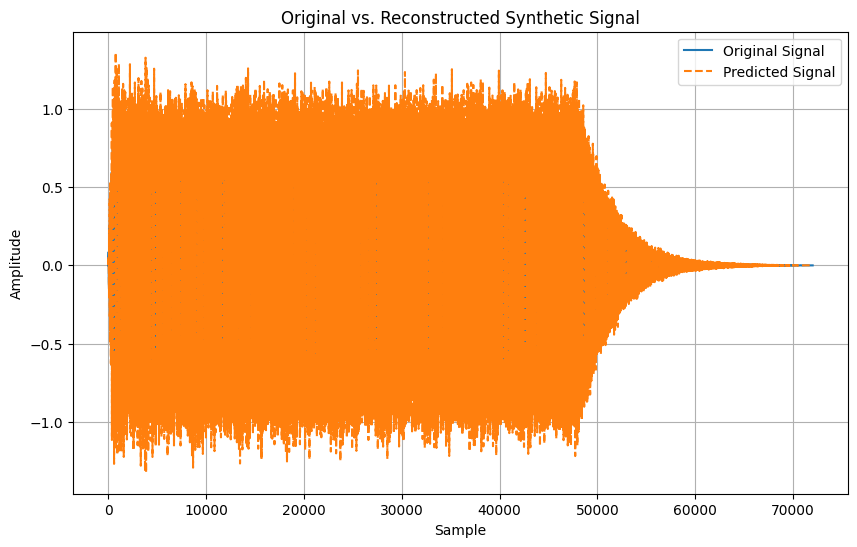

Original


Reconstructed


Compression rate: 77.59%


In [76]:
## SYNTHETIC SOUND
audio_path = '../sounds/synthetic.wav'

sample_rate = 24000

waveform, orig_sample_rate = torchaudio.load(audio_path)
waveform = waveform[:1] # Load first channel of the audio
waveform = torchaudio.functional.resample(waveform, orig_freq=orig_sample_rate, new_freq=sample_rate).squeeze(0) # Resample the audio

# Preprocess the audio
inputs = processor(raw_audio=waveform, sampling_rate=sample_rate, return_tensors="pt")
bandwidths = encodec.config.target_bandwidths

# Encode the audio
target_bandwidth = bandwidths[-1]
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)

codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales
torch.save({"codes": codes, "scales": scales}, "compressed_audio.ecdc")

# compute bandwith
print(f"Target bandwidth: {target_bandwidth:.2f} kbps")
duration = waveform.shape[-1] / sample_rate
# latent codes per second
cps = codes.shape[-2] * codes.shape[-1] / duration
# bits per codebook
bpc = math.log2(encodec.config.codebook_size)
calculated_bandwidth = cps * bpc / 1000
print(f"Calculated bandwidth: {calculated_bandwidth:.2f} kbps")

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

# Plot the original and reconstructed wavefor
plt.figure(figsize=(10, 6))
plt.plot(waveform, label='Original Signal')  # Original test signal, detached
plt.plot(audio.numpy().squeeze(), label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Reconstructed Synthetic Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

print("Original")
display(Audio(waveform, rate=sample_rate))

print("Reconstructed")
display(Audio(audio.numpy().squeeze(), rate=sample_rate))

# Calculate compression rate
original_size = os.path.getsize(audio_path)
compressed_size = os.path.getsize("compressed_audio.ecdc")
compression_rate = (1 - (compressed_size / original_size)) * 100
print(f"Compression rate: {compression_rate:.2f}%")

Target bandwidth: 24.00 kbps
Calculated bandwidth: 24.01 kbps


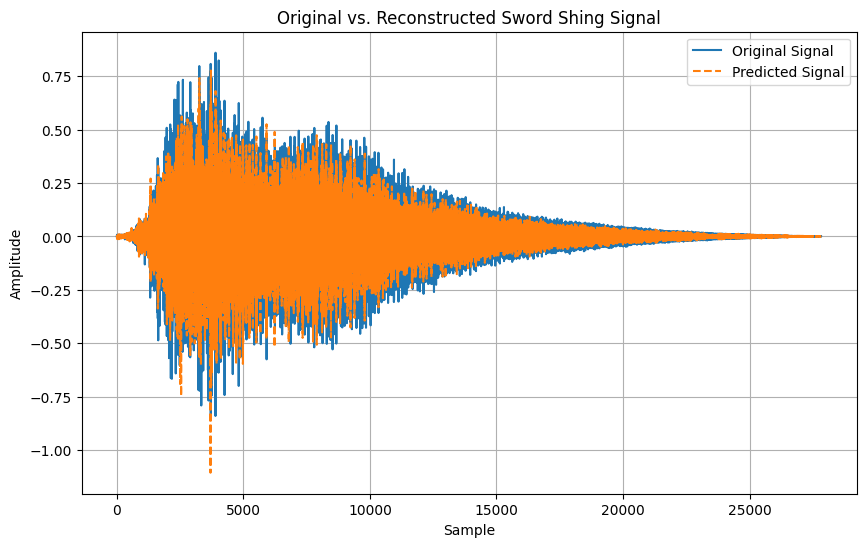

Original


Reconstructed


Compression rate: 76.56%


In [77]:
# SWORD 
audio_path = '../sounds/718782-sword-shing.wav'

sample_rate = 24000

waveform, orig_sample_rate = torchaudio.load(audio_path)
waveform = waveform[:1] # Load first channel of the audio
waveform = torchaudio.functional.resample(waveform, orig_freq=orig_sample_rate, new_freq=sample_rate).squeeze(0) # Resample the audio

# Preprocess the audio
inputs = processor(raw_audio=waveform, sampling_rate=sample_rate, return_tensors="pt")
bandwidths = encodec.config.target_bandwidths

# Encode the audio
target_bandwidth = bandwidths[-1]
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)

codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales
torch.save({"codes": codes, "scales": scales}, "compressed_audio.ecdc")

# compute bandwith
print(f"Target bandwidth: {target_bandwidth:.2f} kbps")
duration = waveform.shape[-1] / sample_rate
# latent codes per second
cps = codes.shape[-2] * codes.shape[-1] / duration
# bits per codebook
bpc = math.log2(encodec.config.codebook_size)
calculated_bandwidth = cps * bpc / 1000
print(f"Calculated bandwidth: {calculated_bandwidth:.2f} kbps")

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

# Plot the original and reconstructed wavefor
plt.figure(figsize=(10, 6))
plt.plot(waveform, label='Original Signal')  # Original test signal, detached
plt.plot(audio.numpy().squeeze(), label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Reconstructed Sword Shing Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

print("Original")
display(Audio(waveform, rate=sample_rate))

print("Reconstructed")
display(Audio(audio.numpy().squeeze(), rate=sample_rate))

# Calculate compression rate
original_size = os.path.getsize(audio_path)
compressed_size = os.path.getsize("compressed_audio.ecdc")
compression_rate = (1 - (compressed_size / original_size)) * 100
print(f"Compression rate: {compression_rate:.2f}%")

Target bandwidth: 24.00 kbps
Calculated bandwidth: 24.02 kbps


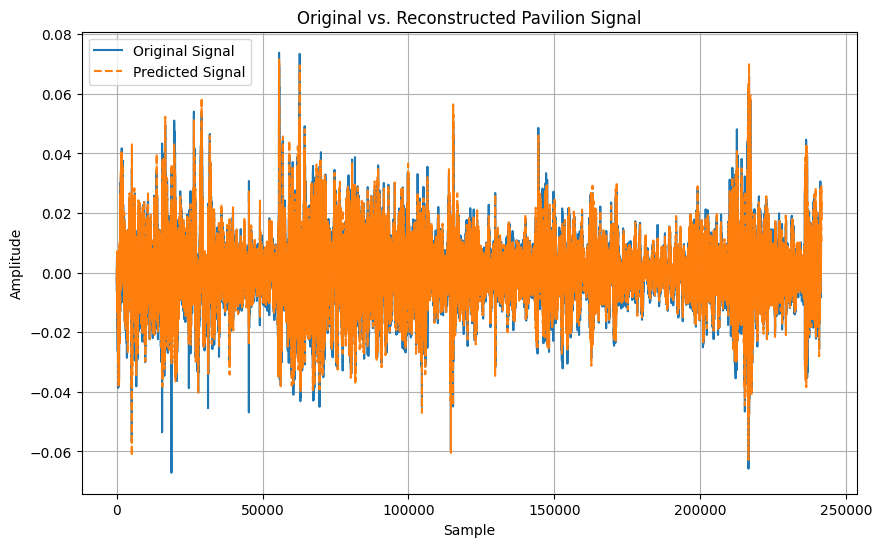

Original


Reconstructed


Compression rate: 79.81%


In [78]:
## PAVILION
audio_path = '../sounds/632748-pavilion.wav'

sample_rate = 24000

waveform, orig_sample_rate = torchaudio.load(audio_path)
waveform = waveform[:1] # Load first channel of the audio
waveform = torchaudio.functional.resample(waveform, orig_freq=orig_sample_rate, new_freq=sample_rate).squeeze(0) # Resample the audio

# Preprocess the audio
inputs = processor(raw_audio=waveform, sampling_rate=sample_rate, return_tensors="pt")
bandwidths = encodec.config.target_bandwidths

# Encode the audio
target_bandwidth = bandwidths[-1]
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)

codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales
torch.save({"codes": codes, "scales": scales}, "compressed_audio.ecdc")

# compute bandwith
print(f"Target bandwidth: {target_bandwidth:.2f} kbps")
duration = waveform.shape[-1] / sample_rate
# latent codes per second
cps = codes.shape[-2] * codes.shape[-1] / duration
# bits per codebook
bpc = math.log2(encodec.config.codebook_size)
calculated_bandwidth = cps * bpc / 1000
print(f"Calculated bandwidth: {calculated_bandwidth:.2f} kbps")

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

# Plot the original and reconstructed wavefor
plt.figure(figsize=(10, 6))
plt.plot(waveform, label='Original Signal')  # Original test signal, detached
plt.plot(audio.numpy().squeeze(), label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Reconstructed Pavilion Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

print("Original")
display(Audio(waveform, rate=sample_rate))

print("Reconstructed")
display(Audio(audio.numpy().squeeze(), rate=sample_rate))

# Calculate compression rate
original_size = os.path.getsize(audio_path)
compressed_size = os.path.getsize("compressed_audio.ecdc")
compression_rate = (1 - (compressed_size / original_size)) * 100
print(f"Compression rate: {compression_rate:.2f}%")

Target bandwidth: 24.00 kbps
Calculated bandwidth: 24.00 kbps


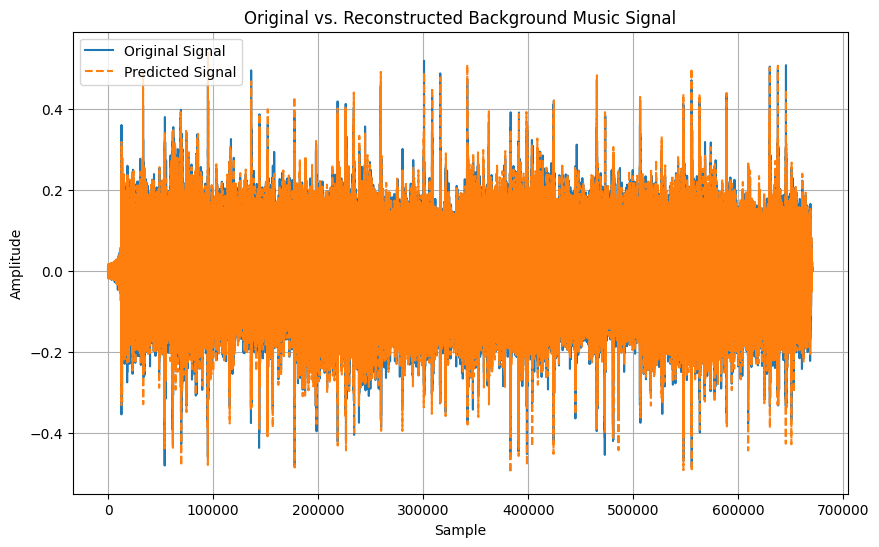

Original


Reconstructed


Compression rate: 78.16%


In [79]:
## BACKGROUND MUSIC
audio_path = '../sounds/750340-background-music.wav'

sample_rate = 24000

waveform, orig_sample_rate = torchaudio.load(audio_path)
waveform = waveform[:1] # Load first channel of the audio
waveform = torchaudio.functional.resample(waveform, orig_freq=orig_sample_rate, new_freq=sample_rate).squeeze(0) # Resample the audio

# Preprocess the audio
inputs = processor(raw_audio=waveform, sampling_rate=sample_rate, return_tensors="pt")
bandwidths = encodec.config.target_bandwidths

# Encode the audio
target_bandwidth = bandwidths[4]
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)

codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales
torch.save({"codes": codes, "scales": scales}, "compressed_audio.ecdc")

# compute bandwith
print(f"Target bandwidth: {target_bandwidth:.2f} kbps")
duration = waveform.shape[-1] / sample_rate
# latent codes per second
cps = codes.shape[-2] * codes.shape[-1] / duration
# bits per codebook
bpc = math.log2(encodec.config.codebook_size)
calculated_bandwidth = cps * bpc / 1000
print(f"Calculated bandwidth: {calculated_bandwidth:.2f} kbps")

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

# Plot the original and reconstructed wavefor
plt.figure(figsize=(10, 6))
plt.plot(waveform, label='Original Signal')  # Original test signal, detached
plt.plot(audio.numpy().squeeze(), label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Reconstructed Background Music Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

print("Original")
display(Audio(waveform, rate=sample_rate))

print("Reconstructed")
display(Audio(audio.numpy().squeeze(), rate=sample_rate))

# Calculate compression rate
original_size = os.path.getsize(audio_path)
compressed_size = os.path.getsize("compressed_audio.ecdc")
compression_rate = (1 - (compressed_size / original_size)) * 100
print(f"Compression rate: {compression_rate:.2f}%")

Target bandwidth: 12.00 kbps
Calculated bandwidth: 12.00 kbps


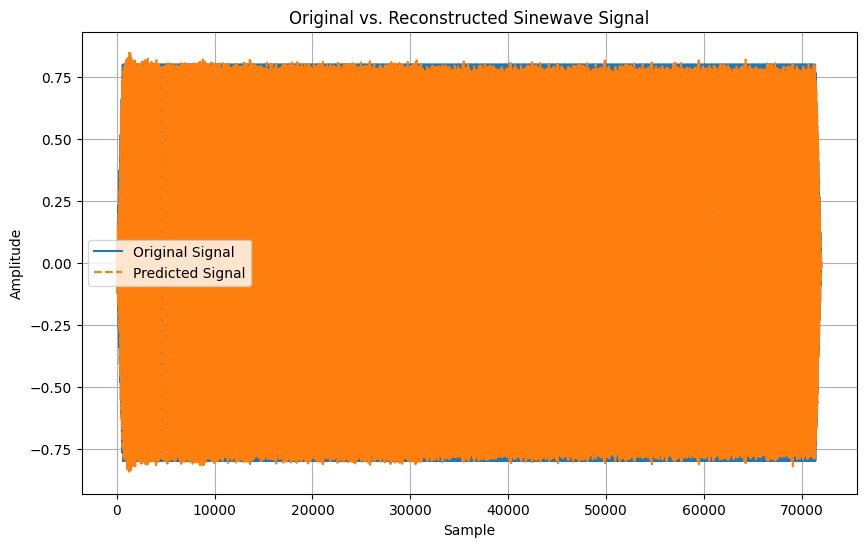

Original


Reconstructed


Compression rate: 88.47%


In [80]:
## HALLWAY
audio_path = '../sounds/sinewave.wav'

sample_rate = 24000

waveform, orig_sample_rate = torchaudio.load(audio_path)
waveform = waveform[:1] # Load first channel of the audio
waveform = torchaudio.functional.resample(waveform, orig_freq=orig_sample_rate, new_freq=sample_rate).squeeze(0) # Resample the audio

# Preprocess the audio
inputs = processor(raw_audio=waveform, sampling_rate=sample_rate, return_tensors="pt")
bandwidths = encodec.config.target_bandwidths

# Encode the audio
target_bandwidth = bandwidths[3]
encoder_outputs = encodec.encode(**inputs, bandwidth=target_bandwidth)

codes = encoder_outputs.audio_codes
scales = encoder_outputs.audio_scales
torch.save({"codes": codes, "scales": scales}, "compressed_audio.ecdc")

# compute bandwith
print(f"Target bandwidth: {target_bandwidth:.2f} kbps")
duration = waveform.shape[-1] / sample_rate
# latent codes per second
cps = codes.shape[-2] * codes.shape[-1] / duration
# bits per codebook
bpc = math.log2(encodec.config.codebook_size)
calculated_bandwidth = cps * bpc / 1000
print(f"Calculated bandwidth: {calculated_bandwidth:.2f} kbps")

# Decode the audio
with torch.no_grad():
  decoder_outputs = encodec.decode(audio_codes=codes, audio_scales=scales)

audio = decoder_outputs.audio_values

# Plot the original and reconstructed wavefor
plt.figure(figsize=(10, 6))
plt.plot(waveform, label='Original Signal')  # Original test signal, detached
plt.plot(audio.numpy().squeeze(), label='Predicted Signal', linestyle='--')  # Model prediction
plt.legend()
plt.title('Original vs. Reconstructed Sinewave Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.grid()
plt.show()

print("Original")
display(Audio(waveform, rate=sample_rate))

print("Reconstructed")
display(Audio(audio.numpy().squeeze(), rate=sample_rate))

# Calculate compression rate
original_size = os.path.getsize(audio_path)
compressed_size = os.path.getsize("compressed_audio.ecdc")
compression_rate = (1 - (compressed_size / original_size)) * 100
print(f"Compression rate: {compression_rate:.2f}%")

**Questions:**

1. Test different bandwidths of the encodec for the hangpan sound. What is the lowest bandwidth that still gives a good reconstruction? What is the compression rate you get for this bandwidth?

    <font color=red> For the Hangpan sound I have tested every available bandwidth from smallest to highest, and then mantained only the results from 12kbps and 24 kbps because the other ones have a bad reconstruction.
    
    I would say that with 12 kbps you still get a decent reconstruction, but not a very very good one, most of the signal sounds the same as the original, but there are some parts where it is noticeable. The "hits" with higher frequency that sound from second 9 until the end of the signal sounds a little bit different. 
    
    Whereas for the highest bandwidth, that is, 24 kbps, this difference in the higher hits is not perceivable, so I would say that with this bandwidth you get a great reconstruction.
    
    In terms of compression we get 89.04% for 12 kbps and 78.15% for 24 kbps. </font>

2. Encode 3 distinct sounds. Does the codec works equally well for all of them? What is the bandwidth threshold after which the quality degradation becomes noticable for all the respective sounds? Where does the difference come from? Support your explanations with necessary plots.

    <font color=red> For this part I have encoded 5 different sounds because none of them had a good reconstruction with the highest bandwidth until I chose the sinewave one. 
    However, every one sounded bad / had a quality degradation in a different way.
    
    Let us start with the synthetic one. The rceonstruction was similar to a sawtooth wave. It reconstructed the correct fundamental frequency and some of the harmonics, but it is not constant over time. There is a lot of noise/distortion that results in this sawtooth wave. We can see in the superposition of the waveforms how the reconstructed one is extremely saturated compared to the original (that we cannot even see).
    

    The next sound chosen was the sword shing. It was a short sound with a lot of high frequencies and not much amplitude. 
    
    This time the result was better. The reconstructed signal is not saturated, in fact it is slightly lower in volume than the original one, but it follows the structure. Perceivably speaking we can recongnize the sound, there is less noise, but the quality degradation is still very noticeable, mostly at the end of the audio.


    The next one was the pavilion. This was the one that sounded best before encoding the sinewave. On the waveform superposition we can see how it reconstructs almost every peak, and some of them with greater magnitude, which results in noise and distortion. 

    In the audio, there is already a lot of noise (real noise, not artificial), which makes the reconstruction harder. However, the codec has been able to reconstruct the speech almost perfectly. The difference between the reconstructed and the original in this case is a low buzzing sound that is constant over all of the audio, similar to the noise that electricity or that fluorescents do. 


    Then we tried with another complex sound like the background music. We didn't really understand why in some cases it was a better reconstruction than in others when the one that has been best reconstructed was the hangpan (at the beginning) and the pavilion, which are very complex sounds.

    On the waveform superposition we can see the same thing as the previous sound: the reconstructed waveform is almost the same as the original one, and this time it is able to reconstruct all of the peaks of the signal, although with slightly less amplitude.

    On the sound we can hear a decent reconstruction of the signal because it is identifiable, however, when you increase a little bit the volume you can clearly hear the noise. This noise is not buzzing, and it is not constant, it follows the rythm of the music.
    This distortion sounds similar to the noise floor of recording devices when nothing is connected to it (hissing noise).
    
    In addition there is a small loss of the highest frequencies, which result in a less richer sound.

    And lastly, since none of them were good enough reconstructions, I decided to try with the simplest sound of all: the sinewave. 
    In this case I did get a good reconstruction with 24 kbps, so I lowered it to 12, and I could already hear some distortions / quality degradations. However, it was barely nothing compared to the rest of the sounds.

    I believe that the difference between the reconstructions does not come from how complex the sound is, since for hangpan, pavilion, and the music it was rather good, but on how many high frequencies are on the signal and how important they are.

    On all reconstructions I have realized that they sounded more flat, as if the highest frequencies were not being correctly reconstructed, and for those signals that contained a lot of high frequencies: the synthetic and the sword shing, are the ones that I got a worse result.
    </font>

___